In [1]:
import numpy as np
from langchain_ollama import ChatOllama
from sklearn.model_selection import ParameterGrid
from sklearn.model_selection import GridSearchCV

from rag_flow import RAGFlow
import pandas as pd
from time import perf_counter
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import requests
from eval import Eval
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

/Users/vilya/Desktop/capstone_project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-10 11:31:27,244 | INFO | No device provided, using mps
2026-10-10 11:31:27,376 | INFO | HTTP Request: HEAD https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 404 Not Found"
2026-10-10 11:31:27,376 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-10-10 11:31:27,378 | INFO | No modules.json found for cross-encoder/ms-marco-MiniLM-L6-v2, initializing a new CrossEncoder model.
2026-10-10 11:31:27,465 | INFO | HTTP Request: GET https://huggingface.co/api/models/cross-encoder/ms-marco-MiniLM-L6-v2 "HTTP/1.1 200 OK"
2026-10-10 11:31:27,561 | INFO | HTTP Request: GE

The goal of this file is to evaluate the quality of the retrieval. The metrics I am going to use:

- Mean Avg Precision @ k. (Penalizes for returning irrelevant documents)
- Mean Recall @ k. (Penalizes for leaving out relevant documents)
- Mean Reciprocal Rank (MRR)
I will use LLM-as_judge to perform my metrics. gpt model is the largest among the ones I have downloaded, so this model will play the role of a judge.

In [2]:
df = pd.read_csv("test_data/arxiv_classifier_300_questions.csv")
questions = df[df["label"] == "arxiv"]["question"]
questions.head(3)

0    What are the main limitations of economic grow...
2    What are the main limitations of operating sys...
3    How can researchers evaluate optical interfere...
Name: question, dtype: str

In [3]:
qwen_answer = ChatOllama(
    model="qwen3:8b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=500,
    num_ctx=3000,
    reasoning=False
)
qwen_query = ChatOllama(
    model="qwen3:8b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=15,
    num_ctx=1024,
    reasoning=False
)

classifier = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0,
    reasoning=False
)


In [4]:
params = {
    "query_model": qwen_query,
    "answer_model": qwen_answer,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "top_k_chunks": 10,
    "classifier": classifier
}

In [5]:
rag = RAGFlow(params)

In [6]:
retrived = []
for question in questions:
    prompt = question
    c = rag._classify_promt(prompt)
    q = rag._generate_arxiv_query(prompt)
    t = rag._retrieve_top_k_titles(q, prompt)
    a = rag._retrieve_articles(t, prompt)
    chunks = rag._get_chunks_fixed_size_with_overlap(a)
    top_chunks = rag._select_top_k_chunks(chunks, prompt)
    retrived.append({
        "question": prompt,
        "all_chunks": chunks,
        "top_chunks": top_chunks,
    })
retrived = pd.DataFrame(retrived).to_csv("retrieval_testing/retrived_chunks.csv")



2026-10-10 11:31:30,034 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:31:31,343 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 8/8 [00:00<00:00, 12.37it/s]
2026-10-10 11:31:35,493 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:31:35,836 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 22/22 [00:01<00:00, 13.11it/s]
2026-10-10 11:31:40,398 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:31:40,736 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 8/8 [00:00<00:00, 11.53it/s]
2026-10-10 11:31:45,384 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:31:45,663 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|███

MuPDF error: format error: cmsOpenProfileFromMem failed



Batches: 100%|██████████| 11/11 [00:00<00:00, 11.73it/s]
2026-10-10 11:35:14,544 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:35:14,822 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 8/8 [00:00<00:00, 12.59it/s]
2026-10-10 11:35:18,262 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:35:18,603 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 10/10 [00:00<00:00, 10.95it/s]
2026-10-10 11:35:25,381 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:35:25,732 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
Batches: 100%|██████████| 7/7 [00:00<00:00, 12.63it/s]
2026-10-10 11:35:30,306 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-10 11:35:30,647 | INFO | HTTP Request: POST http://loc

In [11]:
test_data = pd.read_csv("retrieval_testing/retrived_chunks.csv")


150

My local gpt model is too small to generate a silver standard scroing of the chunkings, so I used my paid ChatGPT account to label the data. I have asked chatGPT to label the retrived top chunks and take 10 other. It is indicated by the retrieval_source column: original - the chunk was retrieved by my system (one of the top chunks), bm25 - it was retrieved my chatGPT using bm25 algo,  and both - the chunk belongs to both pools.

In [115]:
labels = pd.read_csv("retrieval_testing/pooled_candidates_provisional_labels.csv")
labels.head(3)

,question,url,chunk_index,title,text,original_rank,bm25_rank,retrieval_source,relevancy,lexical_score,review_priority,label_method
0,What are the main limitations of economic grow...,https://arxiv.org/pdf/2609.05894,3,The End of AI Exponentiation: Fluttering Insid...,a growing concern that has been observed. It h...,1.0,1.0,both,0,0.0430,normal,provisional_tfidf_not_semantic
1,What are the main limitations of economic grow...,https://arxiv.org/pdf/2609.05894,2,The End of AI Exponentiation: Fluttering Insid...,"concerns, public uncertainty, and geopolitical...",8.0,2.0,both,0,0.0534,normal,provisional_tfidf_not_semantic
2,What are the main limitations of economic grow...,https://arxiv.org/pdf/2609.31236,46,Catch-Up and Come Home: Economic Convergence a...,"of Taiwan and India (Saxenian, 2006), and some...",2.0,7.0,both,0,0.0748,high,provisional_tfidf_not_semantic


In [122]:
print(f"{len(labels[labels["retrieval_source"] == "bm25"])} chunks were retrived only by chatGPT")
count = len(labels[labels["retrieval_source"].isin(["bm25", "both"])])
print(f"{count} chunks were retrieved by both models")
print(f"{len(labels[labels["retrieval_source"] == "original"])} chunks were retrived only by my model")


1055 chunks were retrived only by chatGPT
1410 chunks were retrieved by BM25
1055 chunks were retrived only by my model


In [162]:
import ast
import pandas as pd

combined = []

for _, row in test_data.iterrows():
    question = row["question"]
    top_chunks = row["top_chunks"]

    if isinstance(top_chunks, str):
        top_chunks = ast.literal_eval(top_chunks)

    for i, chunk in enumerate(top_chunks):
        url = chunk["article_url"]
        chunk_index = int(chunk["chunk_index"])

        matches = labels[
            (labels["question"] == question) &
            (labels["url"] == url) &
            (labels["chunk_index"] == chunk_index)
        ]["relevancy"]

        true_relevance = (
            matches.iloc[0] if not matches.empty else None
        )

        combined.append({
            "question": question,
            "url": url,
            "chunk_index": chunk_index,
            "rank": i + 1,
            "true_relevance": true_relevance
        })

combined_df = pd.DataFrame(combined)
combined_df.to_csv("pred_and_true.csv")

In [171]:
import pandas as pd

def precision_at_k(combined_df, k=10):
    results = []

    for question, group in combined_df.groupby("question"):
        top_k = group[
            group["rank"] <= k
        ].sort_values("rank")

        # Пропускаем вопросы с неполной разметкой
        if len(top_k) != k or top_k["true_relevance"].isna().any():
            continue

        precision = top_k["true_relevance"].sum() / k

        results.append({
            "question": question,
            "precision": precision
        })

    return pd.DataFrame(results)



In [191]:
precision_at_k_res = []
for k in range(1, 11):
    avg_precision = np.mean(precision_at_k(combined_df, k)["precision"])
    precision_at_k_res.append({
        "k": k,
        "avg_precision": avg_precision
    })
precision_at_k_res = pd.DataFrame(precision_at_k_res)
precision_at_k_res.to_csv("qwen_semantic_precision_at_k.csv")

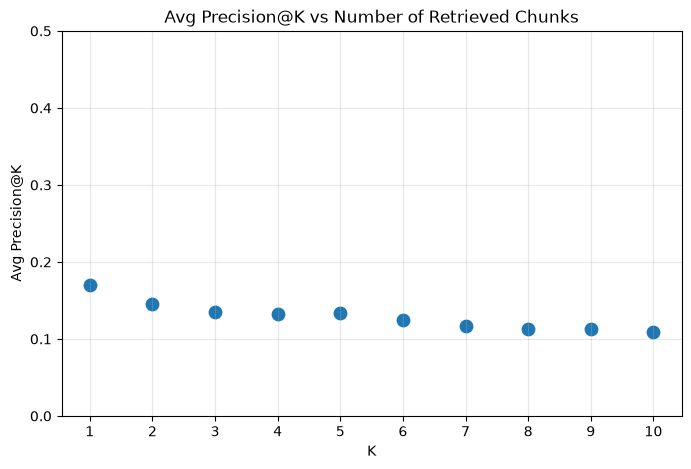

In [184]:
plt.figure(figsize=(8, 5))

plt.scatter(
    precision_at_k_res["k"],
    precision_at_k_res["avg_precision"],
    s=80
)

plt.xlabel("K")
plt.ylabel("Avg Precision@K")
plt.title("Avg Precision@K vs Number of Retrieved Chunks")
plt.xticks(range(1, 11))
plt.ylim(0, 0.5)
plt.grid(alpha=0.3)

plt.show()

In [185]:
import numpy as np
import pandas as pd

def pooled_recall_at_k(combined_df, labels, k=10):
    results = []

    for question, group in combined_df.groupby("question"):
        top_k = group[
            group["rank"] <= k
        ].sort_values("rank")

        # Require complete labels for Top-K
        if len(top_k) != k or top_k["true_relevance"].isna().any():
            continue

        # All known relevant chunks in the pooled dataset
        pool = labels[labels["question"] == question]

        pool = pool[
            pool["relevancy"].isin([0, 1])
        ]

        total_relevant = (
            pool["relevancy"] == 1
        ).sum()

        # Undefined recall when no relevant chunks are known
        if total_relevant == 0:
            continue

        retrieved_relevant = (
            top_k["true_relevance"] == 1
        ).sum()

        recall = retrieved_relevant / total_relevant

        results.append({
            "question": question,
            "recall": recall
        })

    return pd.DataFrame(results)

In [192]:
recall_at_k_res = []

for k in range(1, 11):
    results = pooled_recall_at_k(
        combined_df,
        labels,
        k=k
    )

    avg_recall = (
        results["recall"].mean()
        if not results.empty
        else np.nan
    )

    recall_at_k_res.append({
        "k": k,
        "avg_recall": avg_recall,
        "evaluated_questions": len(results)
    })

recall_df = pd.DataFrame(recall_at_k_res)
recall_df.to_csv("qwen_semantic_recall_at_k.csv")
display(recall_df)

,k,avg_recall,evaluated_questions
0,1,0.155823,52
1,2,0.242735,52
2,3,0.325962,52
3,4,0.418376,52
4,5,0.518964,52
5,6,0.573771,52
6,7,0.618056,52
7,8,0.678686,52
8,9,0.772329,52
9,10,0.823184,52


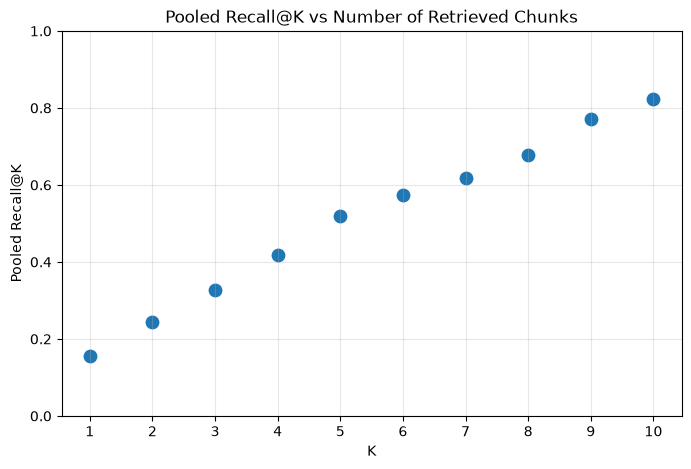

In [187]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    recall_df["k"],
    recall_df["avg_recall"],
    s=80
)

plt.xlabel("K")
plt.ylabel("Pooled Recall@K")
plt.title("Pooled Recall@K vs Number of Retrieved Chunks")
plt.xticks(range(1, 11))
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.show()

In [188]:
import numpy as np
import pandas as pd

def mrr_at_k(combined_df, k=10):
    results = []

    for question, group in combined_df.groupby("question"):
        top_k = group[
            group["rank"] <= k
        ].sort_values("rank")

        # Skip questions with incomplete labels
        if len(top_k) != k or top_k["true_relevance"].isna().any():
            continue

        relevant = top_k[
            top_k["true_relevance"] == 1
        ]

        if relevant.empty:
            reciprocal_rank = 0
        else:
            first_rank = relevant["rank"].iloc[0]
            reciprocal_rank = 1 / first_rank

        results.append({
            "question": question,
            "reciprocal_rank": reciprocal_rank
        })

    return pd.DataFrame(results)

In [193]:
mrr_at_k_res = []

for k in range(1, 11):
    results = mrr_at_k(combined_df, k)

    avg_mrr = (
        results["reciprocal_rank"].mean()
        if not results.empty
        else np.nan
    )

    mrr_at_k_res.append({
        "k": k,
        "avg_mrr": avg_mrr,
        "evaluated_questions": len(results)
    })

mrr_df = pd.DataFrame(mrr_at_k_res)
mrr_df.to_csv("qwen_semantic_mrr.csv")
display(mrr_df)

,k,avg_mrr,evaluated_questions
0,1,0.170213,141
1,2,0.198582,141
2,3,0.210402,141
3,4,0.215721,141
4,5,0.218558,141
5,6,0.218558,141
6,7,0.219571,141
7,8,0.220458,141
8,9,0.222822,141
9,10,0.223531,141


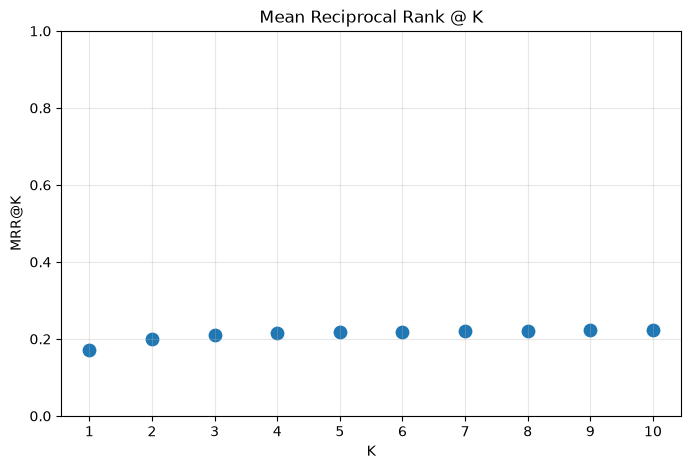

In [190]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    mrr_df["k"],
    mrr_df["avg_mrr"],
    s=80
)

plt.xlabel("K")
plt.ylabel("MRR@K")
plt.title("Mean Reciprocal Rank @ K")
plt.xticks(range(1, 11))
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.show()